# Risk distribution and severity classification

This file contains 
- **Data Cleaning** (but for the final data cleaning, please refer to `clean_data.ipynb`)
- Most importantly **research on severity criterion**, based on categorization in severity bins using several features
- Time distribution (duration of events, monthly/yearly arrivals)

Eventually and for the rest of the project, a continuous monetary damage scale was used as a proxy for severity.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import plotly.express as px
import seaborn as sns
import calendar
import geopandas
import plotly.io as pio
import pysal
import numpy as np
from scipy import stats

sns.set_theme(style='whitegrid')

df = pd.read_excel("../Data/natural_europe_19752025.xlsx")
colors = ["lightgoldenrodyellow", "tomato", "mediumvioletred", "cornflowerblue", "salmon", "lavender", "darkseagreen", "lightcoral", "lightskyblue"]

## Data selection and cleaning

1. We select columns that interest us. 

    **NOTE:** We remove the `CPI` and `Total Damage ('000 US$)` features, as both together yield the `Total Damage, Adjusted ('000 US$)` feature.

2. We add **dates and duration**
    1. All events have a recorded year
    2. We remove events that have no month indicated (29 records)
    3. For events that have a missing `Start Day` or `End Day`, we replace the null value by `1` if it's the start of the event, or by the last day of the corresponding month if it's the end of the event.

    **NOTE: In the following, the `duration_days` column is computed using this inputed data. But this data processing must considered in case duration of the event is a criterion of disaster's gravity.**

<u>**Note:**</u> Later, we chose to remove records with no complete date.

The resulting dataset `data_raw` contains **`2,058`** rows.

In [167]:
columns = ['DisNo.',
           'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 
           'Event Name', 'ISO', 'Country', 'Subregion', 'Location', 'Origin', 
           'Associated Types', 
           'Magnitude', 'Magnitude Scale', 'Latitude', 
           'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 
           'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 
           'No. Affected', 'No. Homeless', 'Total Affected', 
           "Total Damage, Adjusted ('000 US$)"]
data_raw = df[columns].copy()

In [168]:
data_raw = data_raw.dropna(subset = ["Start Month", "End Month"])

data_raw["Start Day"] = data_raw["Start Day"].fillna(1)
temp_end_month = pd.to_datetime({
    'year': data_raw['End Year'].astype(int),
    'month': data_raw['End Month'].astype(int),
    'day': 1,
})
last_days = temp_end_month.dt.days_in_month
data_raw['End Day'] = data_raw['End Day'].fillna(pd.Series(last_days, index=data_raw.index)).astype(int)

data_raw['start_date'] = pd.to_datetime({
        'year': data_raw['Start Year'],
        'month': data_raw['Start Month'].astype(int),
        'day': data_raw['Start Day'],
    })

data_raw['end_date'] = pd.to_datetime({
        'year': data_raw['End Year'],
        'month': data_raw['End Month'].astype(int),
        'day': data_raw['End Day'],
    })
data_raw['duration_days'] = (data_raw['end_date'] - data_raw['start_date']).dt.days

data_raw.drop(["Start Day", "End Year", "End Month", "End Day"], inplace=True, axis=1)
print(f"Total datapoints: {len(data_raw)}")

Total datapoints: 2058


In [101]:
print(f"The dataset contains {len(data_raw)} rows.")

summary_table = pd.DataFrame({
    'Data Type': data_raw.dtypes,
    'Non-Null Count': data_raw.notnull().sum(),
    'Missing (NaN) Count': data_raw.isna().sum(),
    'Missing (%)': (data_raw.isnull().mean() * 100).round(2),
    'Unique Values': data_raw.nunique(dropna=True),
})

summary_table = summary_table.sort_values(by = 'Missing (%)', ascending=False)

pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print(summary_table)

The dataset contains 2058 rows.
                                        Data Type  Non-Null Count  Missing (NaN) Count  Missing (%)  Unique Values
No. Homeless                              float64             133                 1925        93.54             94
Latitude                                  float64             254                 1804        87.66            231
Longitude                                 float64             254                 1804        87.66            234
Event Name                                    str             370                 1688        82.02            111
No. Injured                               float64             382                 1676        81.44            123
River Basin                                   str             419                 1639        79.64            406
Associated Types                              str             531                 1527        74.20             61
Origin                                        st

## Severity criterion

**Note: After consideration, we leave aside `duration_days` as a criterion for disasters severity for now.**

To characterize disasters severity, we consider the following features:
1. `Total Deaths`
2. `Total Damage, Adjusted ('000 US$)` (*values are already adjusted for inflation*)
3. `Magnitude` (which always comes with a `Magnitude Scale`)

In [128]:
severity_candidates = ["Magnitude", "Total Damage, Adjusted ('000 US$)", "Total Deaths"]

# how many rows for each combination of criterion
presence_patterns = (
    data_raw[severity_candidates].notna().rename(columns = {col: f'{col} present?' for col in severity_candidates})
    .replace({True: "Yes", False: "No"}).value_counts().reset_index(name = "Count")
)
presence_patterns["Presence (%)"] = (presence_patterns["Count"] / len(data_raw) * 100).round(2)

df.to_latex(
    "plots/severity_indicators_presence.tex",
    index=False,
    caption="Availability of severity proxies in the dataset.",
    label="tab:disasters",
    float_format="%.2f",
    escape = True
)

presence_patterns

,Magnitude present?,"Total Damage, Adjusted ('000 US$) present?",Total Deaths present?,Count,Presence (%)
0,No,No,Yes,532,25.85
1,No,No,No,367,17.83
2,Yes,No,Yes,288,13.99
3,No,Yes,Yes,260,12.63
4,Yes,Yes,Yes,248,12.05
5,No,Yes,No,172,8.36
6,Yes,No,No,138,6.71
7,Yes,Yes,No,53,2.58


We first look at distribution of these features independently.

**Note:** We add 1 before the log to safely handle zeros. 

1. The first vizualisation comes from **Kernel Density Estimators** (allows for visual distribution)
2. Then we plot **logarithmic distributions** and assess **goodness of fit**

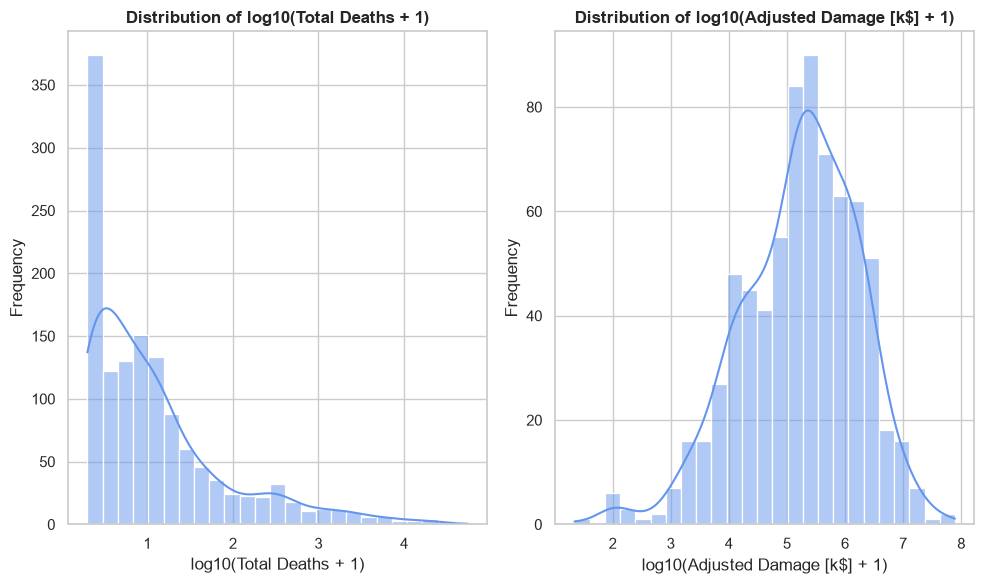

In [103]:
severity_candidates = {
    'Total Deaths': 'Deaths',
    "Total Damage, Adjusted ('000 US$)": 'Damage_kUSD',
}

viz_df = data_raw[list(severity_candidates.keys())].rename(columns = severity_candidates).copy()

for col in ['Deaths', 'Damage_kUSD']:
    viz_df[f'log_{col}'] = np.log10(viz_df[col].fillna(0) + 1)

fig, axes = plt.subplots(1, 2, figsize = (10, 6))
metrics = [
    ('log_Deaths', 'log10(Total Deaths + 1)'),
    ('log_Damage_kUSD', 'log10(Adjusted Damage [k$] + 1)'),
]

for ax, (col, label) in zip(axes, metrics):
    sns.histplot(
        viz_df[viz_df[col] > 0][col],
        kde = True,
        ax = ax,
        color = 'cornflowerblue',
        bins = 25,
    )
    ax.set_title(f'Distribution of {label}', fontweight = "bold")
    ax.set_xlabel(label)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

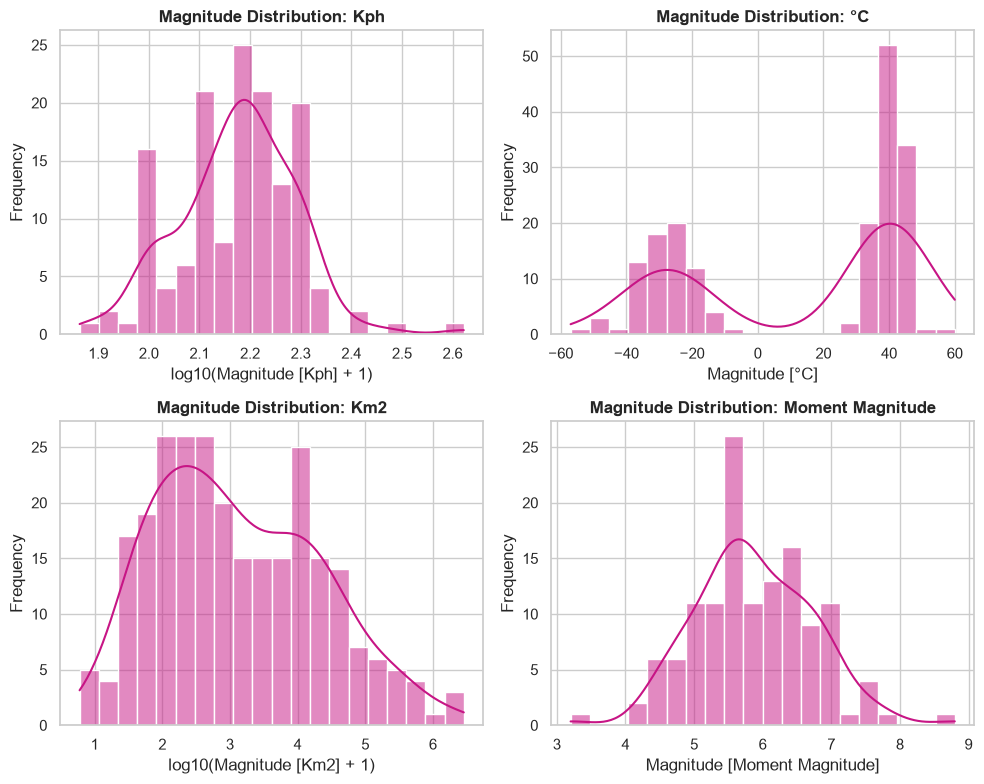

In [104]:
mag_df = data_raw[['Magnitude', 'Magnitude Scale']].dropna().copy()

units = mag_df['Magnitude Scale'].unique()

log_units = ['Km2', 'Vaccinated', 'Kph']

n_units = len(units)
cols = 2
rows = int(np.ceil(n_units / cols))

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
axes = np.array(axes).flatten()

for i, unit in enumerate(units):
    ax = axes[i]
    subset = mag_df[mag_df['Magnitude Scale'] == unit]['Magnitude']

    if unit in log_units:
        plot_data = np.log10(subset[subset > 0] + 1)
        x_label = f'log10(Magnitude [{unit}] + 1)'
    else:
        plot_data = subset
        x_label = f'Magnitude [{unit}]'

    sns.histplot(
        plot_data,
        kde=True,
        ax=ax,
        color='mediumvioletred',
        bins=20,
    )
    ax.set_title(f'Magnitude Distribution: {unit}', fontweight='bold')
    ax.set_xlabel(x_label)
    ax.set_ylabel('Frequency')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

FITTED LOGNORMAL PARAMETERS FOR ADJUSTED DAMAGE ('000 US$):
  scipy.stats.lognorm params: s=2.327079, loc=0.000000, scale=164200.192344
  Underlying normal:          mu=12.008842, sigma=2.327079


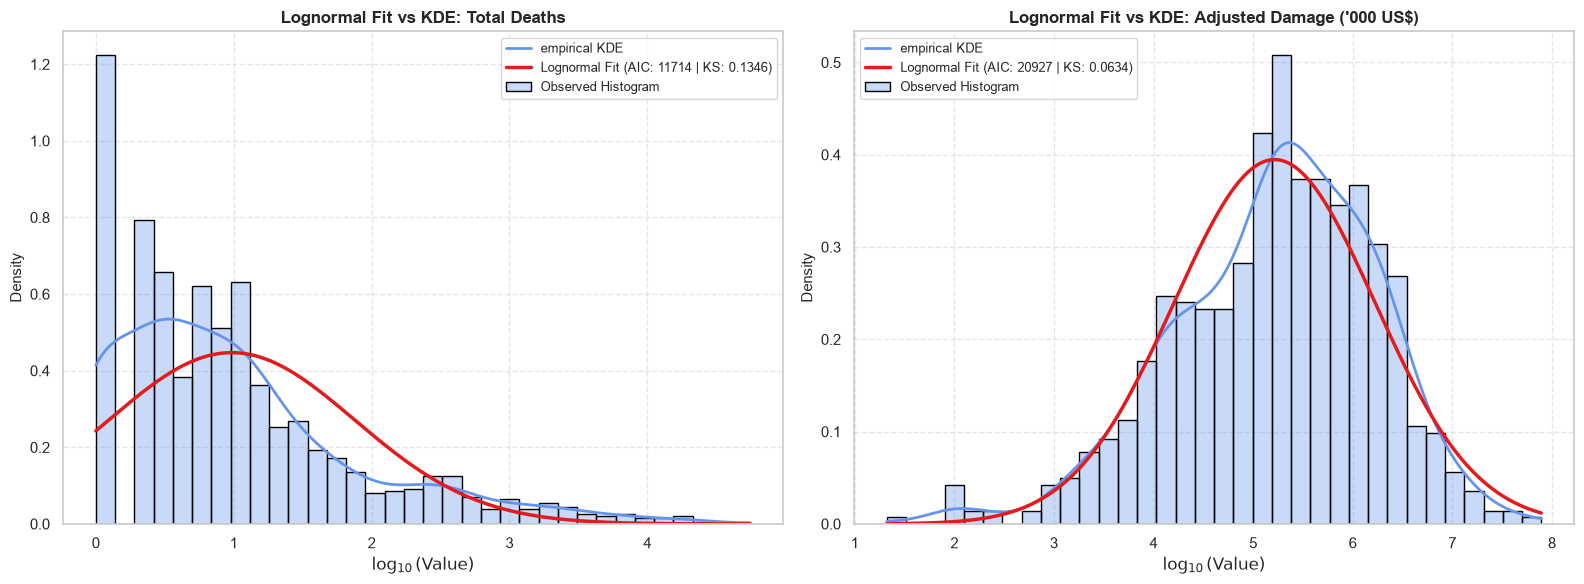

,Feature,sigma (std of ln X),mu (mean of ln X),Median (exp(mu)),Log-Likelihood,AIC,BIC,KS Stat,p-value
0,Total Deaths,2.0547,2.2698,9.68,-5855.02,11714.05,11724.43,0.1346,0.0000
1,Adjusted Damage ('000 US$),2.3271,12.0088,164200.19,-10461.66,20927.33,20936.52,0.0634,0.0052


In [160]:
F = [
    ('Total Deaths', data_raw['Total Deaths']),
    ("Adjusted Damage ('000 US$)", data_raw["Total Damage, Adjusted ('000 US$)"]),
]

results = []
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

adjusted_damage_params = {}

for ax, (title, series) in zip(axes, F):
    data_clean = series.dropna()
    x_vals = data_clean[data_clean > 0].to_numpy()
    n = len(x_vals)

    shape, loc, scale = stats.lognorm.fit(x_vals, floc=0)
    params = (shape, loc, scale)

    # mu and sigma of ln(X)
    sigma = shape
    mu = np.log(scale)
    theoretical_median = scale

    if "Adjusted Damage" in title:
        damage_fit_params = {
            "shape (s/sigma)": shape,
            "loc": loc,
            "scale": scale,
            "mu (mean of ln X)": mu,
        }
        print("=" * 60)
        print("FITTED LOGNORMAL PARAMETERS FOR ADJUSTED DAMAGE ('000 US$):")
        print(f"  scipy.stats.lognorm params: s={shape:.6f}, loc={loc:.6f}, scale={scale:.6f}")
        print(f"  Underlying normal:          mu={mu:.6f}, sigma={sigma:.6f}")
        print("=" * 60)

    k = 2
    log_lik = np.sum(stats.lognorm.logpdf(x_vals, *params))
    aic = 2 * k - 2 * log_lik
    bic = k * np.log(n) - 2 * log_lik
    ks_stat, p_val = stats.kstest(x_vals, 'lognorm', args=params)

    results.append({
        'Feature': title,
        'sigma (std of ln X)': round(sigma, 4),
        'mu (mean of ln X)': round(mu, 4),
        'Median (exp(mu))': round(theoretical_median, 2),
        'Log-Likelihood': round(log_lik, 2),
        'AIC': round(aic, 2),
        'BIC': round(bic, 2),
        'KS Stat': round(ks_stat, 4),
        'p-value': round(p_val, 4),
    })

    log_x = np.log10(x_vals)

    sns.histplot(
        log_x,
        bins=np.linspace(log_x.min(), log_x.max(), 35),
        stat='density',
        kde=True,
        ax=ax,
        color='cornflowerblue',
        edgecolor='black',
        alpha=0.35,
        line_kws={'color': 'darkblue', 'linewidth': 2, 'label': 'empirical KDE'},
        label='Observed Histogram',
    )

    # 2. Fitted Theoretical Distribution via change-of-variables
    y_grid = np.linspace(log_x.min(), log_x.max(), 400)
    x_grid = 10**y_grid
    pdf_log = stats.lognorm.pdf(x_grid, *params) * x_grid * np.log(10)

    ax.plot(
        y_grid,
        pdf_log,
        color='#e41a1c',
        linewidth=2.5,
        label=f'Lognormal Fit (AIC: {aic:.0f} | KS: {ks_stat:.4f})',
    )

    ax.set_title(f'Lognormal Fit vs KDE: {title}', weight='bold')
    ax.set_xlabel(r'$\log_{10}(\text{Value})$')
    ax.set_ylabel('Density', fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig(
    "plots/severity_indicators_fits.pdf",
    format="pdf",
    bbox_inches="tight", 
    pad_inches=0.05 
)

plt.show()

summary_df = pd.DataFrame(results)
display(summary_df)

In [106]:
for title, series in F:
    x_vals = series.dropna()[lambda x: x > 0].to_numpy()
    shape, loc, scale = stats.lognorm.fit(x_vals, floc=0)

    sigma = shape
    mu = np.log(scale)

    theoretical_median = np.exp(mu)
    theoretical_mean = np.exp(mu + 0.5 * sigma**2)
    theoretical_std = np.sqrt(
        (np.exp(sigma**2) - 1) * np.exp(2 * mu + sigma**2)
    )

    print(f'FITTED LOGNORMAL DISTRIBUTION: {title}')
    print(f'Parameters (of the Normal distribution of ln(variable)):  mu = {mu:.4f},  sigma = {sigma:.4f}')
    print(f'Median (of original value):      {theoretical_median:,.2f}')
    print(f'Mean (of original value):        {theoretical_mean:,.2f}')
    print(f'Std Dev (of original value):     {theoretical_std:,.2f}\n')

FITTED LOGNORMAL DISTRIBUTION: Total Deaths
Parameters (of the Normal distribution of ln(variable)):  mu = 2.2698,  sigma = 2.0547
Median (of original value):      9.68
Mean (of original value):        79.89
Std Dev (of original value):     654.69

FITTED LOGNORMAL DISTRIBUTION: Adjusted Damage ('000 US$)
Parameters (of the Normal distribution of ln(variable)):  mu = 12.0088,  sigma = 2.3271
Median (of original value):      164,200.19
Mean (of original value):        2,462,011.76
Std Dev (of original value):     36,833,123.83



## Data severity classification

We propose two severity classifications:
1. Based on *A universal severity classification for natural disasters* by Caldera et al (2021), we re-use their fatality and damages thresholds to categorize events by their absolute values. Although their paper introduces 10 severity levels, they restrict natural disasters to 6 levels.

2. Similarly to Klibi et al in *Scenario-based Supply Chain Network risk modeling* (2012), we classifiy events in 4 categories [`minor`, `moderate`, `severe`, `catastrophic`] based on percentiles. A first attempt using the values used in the paper led to unsatisfactory results, and we converged to percentile values `[0.50, 0.80, 0.90, 1.0]`

Considering that we account for several scaled factors (Deaths, Damage), we consider two ways to attribute final severity labels:
1. **Worst-case scenario**: we take the worst per-feature severity value as the event overall severity
2. **Weighted**: we take an average of per-feature severities

**NOTE: We input the missing severity values with the lowest baseline to compute overall severity of the event.**

### The absolute classification approach

In [136]:
fatality_bins = [0, 1, 10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000, 100_000_000, 1_000_000_000]
damage_bins = [0, 1, 10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000, 100_000_000, 1_000_000_000]
LABELS = list(range(len(fatality_bins) - 1))
data1_severity = data_raw.copy()

has_any_severity = data1_severity[["Total Deaths", "Total Damage, Adjusted ('000 US$)"]].notna().any(axis=1)
data1_severity = data1_severity[has_any_severity].copy()

# compute levels of fatalities and damage
data1_severity["fatality_level"] = pd.cut(data1_severity["Total Deaths"].fillna(0), # Conceptual choice!!
                                          bins = fatality_bins, labels = LABELS, right = False).astype(int)
data1_severity["damage_level"] = pd.cut(data1_severity["Total Damage, Adjusted ('000 US$)"].fillna(0), 
                                          bins = damage_bins, labels = LABELS, right = False).astype(int)

print(len(data1_severity))

1553


In [137]:
# OVERALL SEVERITY
data1_severity["overall_level_max"] = data1_severity[["fatality_level", "damage_level"]].max(axis = 1)
data1_severity["overall_level_avg"] = data1_severity[["fatality_level", "damage_level"]].mean(axis = 1)

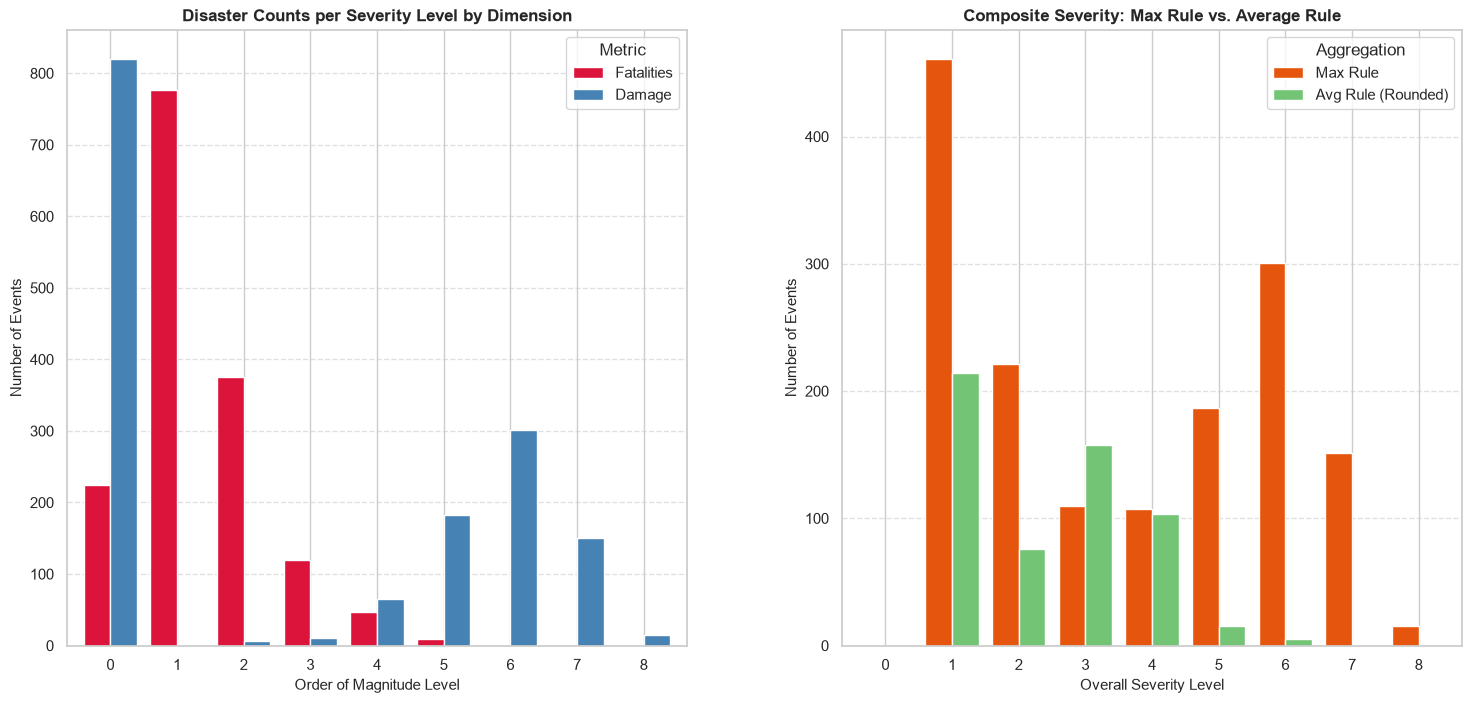

In [138]:
max_observed_level = max(
    data1_severity['fatality_level'].max(),
    data1_severity['damage_level'].max(),
    data1_severity['overall_level_max'].max(),
)
full_idx = list(range(max_observed_level + 1))

fig = plt.figure(figsize=(18, 8))
grid = plt.GridSpec(1, 2, hspace=0.35, wspace=0.25)

ax_bar = fig.add_subplot(grid[0, 0])
level_dist = pd.DataFrame({
    'Fatalities': data1_severity['fatality_level'].value_counts(),
    'Damage': data1_severity['damage_level'].value_counts(),
}).reindex(full_idx, fill_value=0)

level_dist.plot(kind='bar', ax=ax_bar, color=['crimson', 'steelblue'], width=0.8)
ax_bar.set_title(
    'Disaster Counts per Severity Level by Dimension',
    weight='bold',
    fontsize=12,
)
ax_bar.set_xlabel('Order of Magnitude Level', fontsize=11)
ax_bar.set_ylabel('Number of Events', fontsize=11)
ax_bar.set_xticklabels(full_idx, rotation=0)
ax_bar.legend(title='Metric')
ax_bar.grid(axis='y', linestyle='--', alpha=0.6)

ax_comp = fig.add_subplot(grid[0, 1])
overall_comp = pd.DataFrame({
    'Max Rule': data1_severity['overall_level_max'].value_counts(),
    'Avg Rule (Rounded)': data1_severity['overall_level_avg'].value_counts(),
}).reindex(full_idx, fill_value=0)

overall_comp.plot(
    kind='bar', ax=ax_comp, color=['#e6550d', '#74c476'], width=0.8
)
ax_comp.set_title(
    'Composite Severity: Max Rule vs. Average Rule', weight='bold', fontsize=12
)
ax_comp.set_xlabel('Overall Severity Level', fontsize=11)
ax_comp.set_ylabel('Number of Events', fontsize=11)
ax_comp.set_xticklabels(full_idx, rotation=0)
ax_comp.legend(title='Aggregation')
ax_comp.grid(axis='y', linestyle='--', alpha=0.6)

plt.savefig(
    "plots/severity1.pdf",
    format="pdf",
    bbox_inches="tight", 
    pad_inches=0.05 
)

plt.show()

### The percentile classification approach

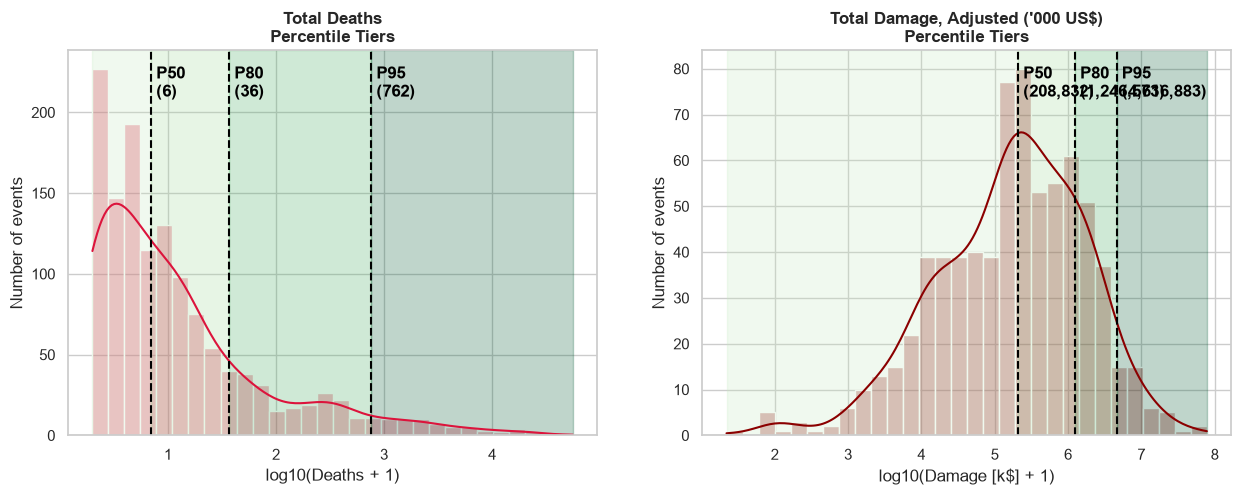

In [139]:
PERCENTILES_CUTOFFS = [0.0, 0.50, 0.80, 0.95, 1.0]
LABELS = ['Low', 'Medium', 'High', 'Extreme']
TIER_RANK = {'Low': 1, 'Medium': 2, 'High': 3, 'Extreme': 4}
INV_TIER_RANK = {v: k for k, v in TIER_RANK.items()}
TIER_COLORS = ['#c7e9c0', '#a1d99b', '#41ab5d', '#005a32']
N_BINS = 30
data2_severity = data_raw.copy()
has_any_severity = data2_severity[["Total Deaths", "Total Damage, Adjusted ('000 US$)"]].notna().any(axis=1)
data2_severity = data2_severity[has_any_severity].copy()

# compute empirical quantiles boundaries 
for c in ["Total Deaths", "Total Damage, Adjusted ('000 US$)"]:
    quantiles = data2_severity[c].quantile(PERCENTILES_CUTOFFS).values
    quantiles = np.unique(quantiles)
    tier_labels = LABELS[:len(quantiles) - 1]
    data2_severity[f'{c}_tier'] = pd.cut(data2_severity[c], bins = quantiles, labels = tier_labels, include_lowest = True)

data2_severity["fatality_level"] = data2_severity["Total Deaths_tier"].map(TIER_RANK).fillna(1).astype(int)
data2_severity["damage_level"] = data2_severity["Total Damage, Adjusted ('000 US$)_tier"].map(TIER_RANK).fillna(1).astype(int)

# ============= VISUALIZATION =============
metrics = [('Total Deaths', 'log10(Deaths + 1)', 'crimson'),
           ("Total Damage, Adjusted ('000 US$)", 'log10(Damage [k$] + 1)', 'darkred')]

fig, axes = plt.subplots(1, 2, figsize=(15,5))
for ax, (col, label, c) in zip(axes, metrics) :
    series_raw = data2_severity[col].dropna()
    log_series_raw = np.log10(series_raw + 1)

    sns.histplot(log_series_raw, kde = True, ax = ax, color = c, bins = N_BINS, alpha = 0.3)
    quantiles_raw = series_raw.quantile(PERCENTILES_CUTOFFS).values
    log_quantiles_raw = np.log10(quantiles_raw + 1)

    # verticale lines for each percentile + adding colors per percentile region
    for p, q_log, q_raw in zip(PERCENTILES_CUTOFFS[1:-1], log_quantiles_raw[1:-1], quantiles_raw[1:-1]):
            ax.axvline(q_log, color='black', linestyle='--', linewidth=1.5)
            ax.text(
                q_log,
                ax.get_ylim()[1] * 0.88,
                f' P{int(p*100)}\n ({q_raw:,.0f})',
                color = 'black',
                weight = 'bold',
            )
    for i in range(len(log_quantiles_raw) - 1) :
         ax.axvspan(log_quantiles_raw[i], log_quantiles_raw[i+1], color = TIER_COLORS[i], alpha = 0.25)

    ax.set_title(f'{col}\nPercentile Tiers', fontsize=12, weight='bold')
    ax.set_xlabel(label)
    ax.set_ylabel("Number of events")

In [140]:
# OVERALL SEVERITY

# HERE WE INPUT LOWEST SEVERITY VALUE - WE MAKE A CONCEPTUAL CHOICE
data2_severity["overall_level_max"] = data2_severity[["fatality_level", "damage_level"]].max(axis = 1)
data2_severity["overall_level_avg"] = data2_severity[["fatality_level", "damage_level"]].mean(axis = 1).round()

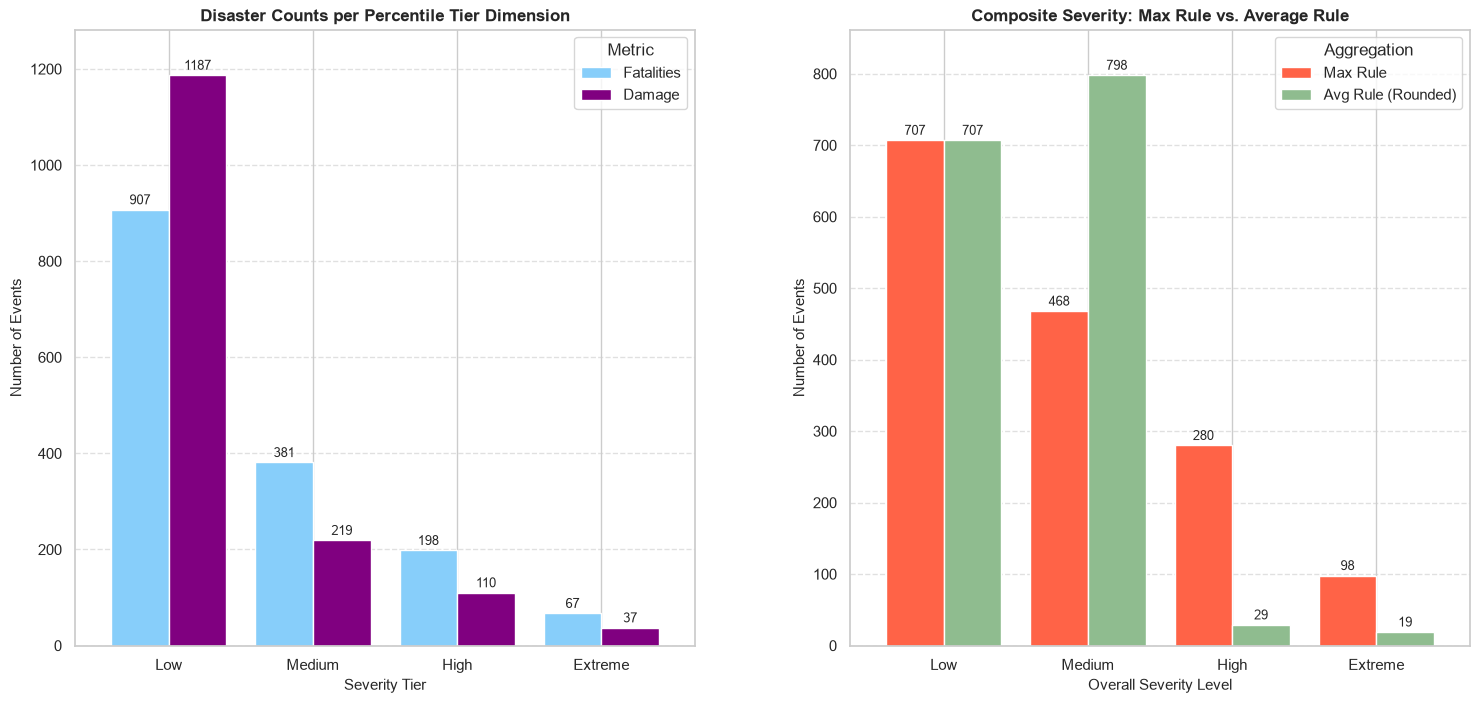

In [141]:
PERCENTILE_INDICES = [1, 2, 3, 4]

fig = plt.figure(figsize=(18, 8))
grid = plt.GridSpec(1, 2, hspace=0.35, wspace=0.25)

ax_bar = fig.add_subplot(grid[0, 0])
level_dist = pd.DataFrame({
    'Fatalities': data2_severity['fatality_level'].value_counts(),
    'Damage': data2_severity['damage_level'].value_counts(),
}).reindex(PERCENTILE_INDICES, fill_value=0)

level_dist.plot(kind='bar', ax=ax_bar, color=['lightskyblue', 'purple'], width=0.8)
ax_bar.set_title(
    'Disaster Counts per Percentile Tier Dimension',
    weight='bold',
    fontsize=12,
)
ax_bar.set_xlabel('Severity Tier', fontsize=11)
ax_bar.set_ylabel('Number of Events', fontsize=11)
ax_bar.set_xticklabels(LABELS, rotation=0)
ax_bar.legend(title='Metric')
ax_bar.grid(axis='y', linestyle='--', alpha=0.6)

for p in ax_bar.patches:
    h = p.get_height()
    if h > 0:
        ax_bar.annotate(
            f'{int(h)}',
            (p.get_x() + p.get_width() / 2.0, h),
            ha='center',
            va='bottom',
            fontsize=9,
            xytext=(0, 2),
            textcoords='offset points',
        )

ax_comp = fig.add_subplot(grid[0, 1])
overall_comp = pd.DataFrame({
    'Max Rule': data2_severity['overall_level_max'].value_counts(),
    'Avg Rule (Rounded)': data2_severity['overall_level_avg'].value_counts(),
}).reindex(PERCENTILE_INDICES, fill_value=0)

overall_comp.plot(
    kind='bar', ax=ax_comp, color=['tomato', 'darkseagreen'], width=0.8
)
ax_comp.set_title(
    'Composite Severity: Max Rule vs. Average Rule', weight='bold', fontsize=12
)
ax_comp.set_xlabel('Overall Severity Level', fontsize=11)
ax_comp.set_ylabel('Number of Events', fontsize=11)
ax_comp.set_xticklabels(LABELS, rotation=0)
ax_comp.legend(title='Aggregation')
ax_comp.grid(axis='y', linestyle='--', alpha=0.6)

for p in ax_comp.patches:
    h = p.get_height()
    if h > 0:
        ax_comp.annotate(
            f'{int(h)}',
            (p.get_x() + p.get_width() / 2.0, h),
            ha='center',
            va='bottom',
            fontsize=9,
            xytext=(0, 2),
            textcoords='offset points',
        )

ax_bar.set_ylim(0, level_dist.values.max() * 1.08)
ax_comp.set_ylim(0, overall_comp.values.max() * 1.08)

plt.savefig(
    "plots/severity2.pdf",
    format="pdf",
    bbox_inches="tight", 
    pad_inches=0.05 
)

plt.show()

## Time-distribution of disasters

In [ ]:
data_chrono = data_raw[["DisNo.", "Disaster Subgroup", "Disaster Subtype", "Country", "Subregion", "Start Year", "Start Month", "start_date", "end_date", "duration_days"]].copy()
START_YEAR = 2000

YEAR_RANGE = pd.Index(range(START_YEAR, 2026), name = "start_year")
data_chrono = data_chrono[data_chrono["Start Year"] >= START_YEAR]

In [119]:
# disaster counts: per year and per month
disasters_year_count = data_chrono.groupby("Start Year")["DisNo."].count().reindex(YEAR_RANGE, fill_value = 0)
yearly_counts = disasters_year_count.values
print("SUMMARY of YEARLY DISASTERS COUNTS:")
print(disasters_year_count.describe())

data_chrono["start_date"] = pd.to_datetime(data_chrono["start_date"])
data_chrono["year_month"] = data_chrono["start_date"].dt.to_period("M")

MONTH_START = f"{START_YEAR}-01"
MONTH_END = "2025-12"
MONTH_RANGE = pd.period_range(MONTH_START, MONTH_END, freq="M")

disasters_month_count = data_chrono[data_chrono["year_month"] >= pd.Period(MONTH_START, freq="M")].groupby("year_month")["DisNo."].count().reindex(MONTH_RANGE, fill_value=0)
monthly_counts = disasters_month_count.values

print("\nSUMMARY of MONTHLY DISASTERS COUNTS:")
print(disasters_month_count.describe())

SUMMARY of YEARLY DISASTERS COUNTS:
count    26.000000
mean     54.692308
std      19.359275
min      16.000000
25%      46.250000
50%      53.000000
75%      64.500000
max      94.000000
Name: DisNo., dtype: float64

SUMMARY of MONTHLY DISASTERS COUNTS:
count    312.000000
mean       4.557692
std        5.343795
min        0.000000
25%        1.000000
50%        3.000000
75%        6.000000
max       47.000000
Name: DisNo., dtype: float64


In [162]:
# Maximum Likelihood Estimation for Negative Binomial
def nll_nbinom(params, y):
    n, p = params
    if n <= 0 or p <= 0 or p >= 1:
        return 1e10
    return -np.sum(stats.nbinom.logpmf(y, n, p))

Fitted Poisson: lambda = 54.69
Fitted Negative Binomial: n = 8.44, p = 0.1338
Fitted lognormal: shape = 0.4073, scale = 50.86


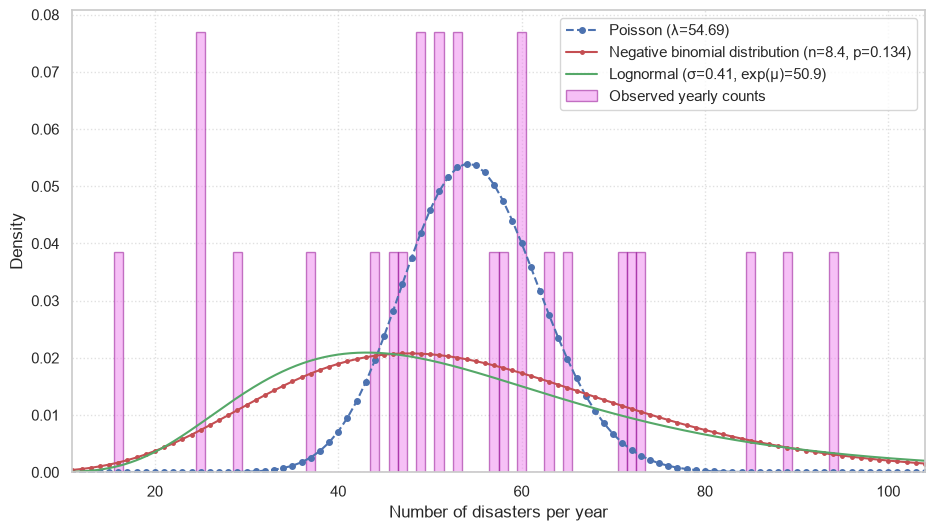

In [123]:
# FIT of YEARLY DISASTER COUNTS
lambda_year = np.mean(yearly_counts)
var_year = np.var(yearly_counts, ddof = 1)
p = lambda_year / var_year if var_year > lambda_year else 0.5
n = (lambda_year**2) / (var_year - lambda_year) if var_year > lambda_year else 0.5

r_year = minimize(nll_nbinom, x0 = [n, p], args = (yearly_counts, ), bounds = [(1e-4, None), (1e-4, 0.9999)])
n_year, p_year = r_year.x

yearly_counts_pos = np.where(yearly_counts == 0, 0.5, yearly_counts)
shape_ln_year, _, scale_ln_year = stats.lognorm.fit(yearly_counts_pos, floc = 0)

print(f"Fitted Poisson: lambda = {lambda_year:.2f}")
print(f"Fitted Negative Binomial: n = {n_year:.2f}, p = {p_year:.4f}")
print(f"Fitted lognormal: shape = {shape_ln_year:.4f}, scale = {scale_ln_year:.2f}")

plt.figure(figsize = (11, 6))
k_min = int(max(0, np.min(yearly_counts) - 5))
k_max = int(np.max(yearly_counts) + 10)
k_discrete = np.arange(k_min, k_max + 1)
k_cont = np.linspace(max(0.1, k_min), k_max, 500)
bins_year = np.arange(k_min - 0.5, k_max + 1.5, 1)

# adding all three fitted distributions
plt.plot(k_discrete, stats.poisson.pmf(k_discrete, mu = lambda_year), "b--", marker = "o", markersize = 4, label = f"Poisson (λ={lambda_year:.2f})")
plt.plot(k_discrete, stats.nbinom.pmf(k_discrete, n_year, p_year), "r-", marker = "o", markersize = 2.5, label = f"Negative binomial distribution (n={n_year:.1f}, p={p_year:.3f})")
plt.plot(k_cont, stats.lognorm.pdf(k_cont, shape_ln_year, 0, scale_ln_year), "g", label = f"Lognormal (σ={shape_ln_year:.2f}, exp(μ)={scale_ln_year:.1f})")

plt.hist(yearly_counts, bins = bins_year, density = True, alpha = 0.5, color = "violet", edgecolor = "darkmagenta", label = "Observed yearly counts")
plt.xlabel("Number of disasters per year")
plt.ylabel("Density")
plt.xlim(k_min, k_max)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

Fitted Poisson: lambda = 4.56
Fitted Negative Binomial: n = 1.20, p = 0.2081
Fitted lognormal: shape = 1.0399, scale = 2.77
312


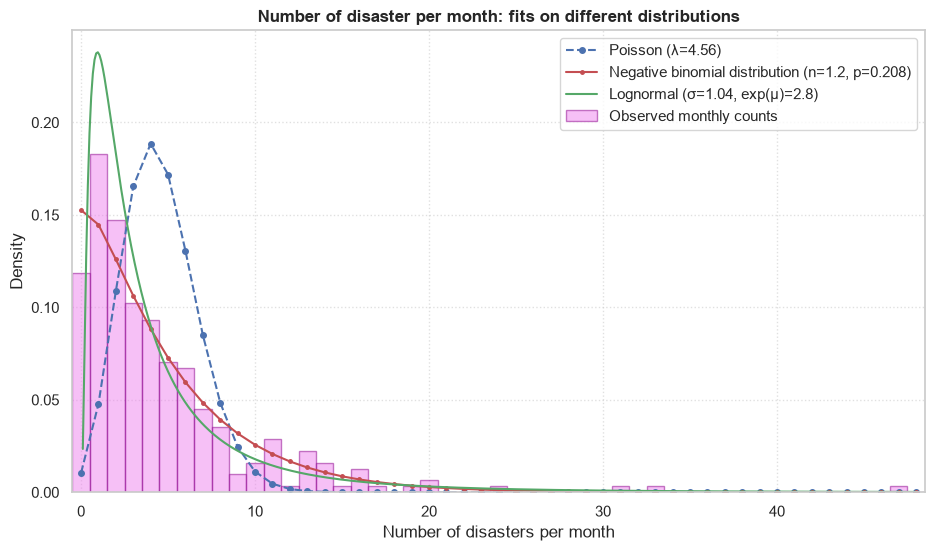

In [164]:
# FIT of MONTHLY DISASTER COUNTS
lambda_month = np.mean(monthly_counts)
var_month = np.var(monthly_counts, ddof = 1)
p = lambda_month / var_month if var_month > lambda_month else 0.5
n = (lambda_month**2) / (var_month - lambda_month) if var_month > lambda_month else 0.5

r_month = minimize(nll_nbinom, x0 = [n, p], args = (monthly_counts, ), bounds = [(1e-4, None), (1e-4, 0.9999)])
n_month, p_month = r_month.x

monthly_counts_pos = np.where(monthly_counts == 0, 0.5, monthly_counts)
shape_ln_month, _, scale_ln_month = stats.lognorm.fit(monthly_counts_pos, floc = 0)

print(f"Fitted Poisson: lambda = {lambda_month:.2f}")
print(f"Fitted Negative Binomial: n = {n_month:.2f}, p = {p_month:.4f}")
print(f"Fitted lognormal: shape = {shape_ln_month:.4f}, scale = {scale_ln_month:.2f}")

print(len(monthly_counts))

plt.figure(figsize = (11, 6))
# k_min = int(max(0, np.min(monthly_counts) - 5))
# k_max = int(np.max(monthly_counts) + 2)
k_min = 0
k_max = int(np.max(monthly_counts) + 1)
k_discrete = np.arange(k_min, k_max + 1)
k_cont = np.linspace(max(0.1, k_min), k_max, 500)
bins_month = np.arange(k_min - 0.5, k_max + 1.5, 1)

# adding all three fitted distributions
plt.plot(k_discrete, stats.poisson.pmf(k_discrete, mu = lambda_month), "b--", marker = "o", markersize = 4, label = f"Poisson (λ={lambda_month:.2f})")
plt.plot(k_discrete, stats.nbinom.pmf(k_discrete, n_month, p_month), "r-", marker = "o", markersize = 2.5, label = f"Negative binomial distribution (n={n_month:.1f}, p={p_month:.3f})")
plt.plot(k_cont, stats.lognorm.pdf(k_cont, shape_ln_month, 0, scale_ln_month), "g", label = f"Lognormal (σ={shape_ln_month:.2f}, exp(μ)={scale_ln_month:.1f})")

plt.hist(monthly_counts, bins = bins_month, density = True, alpha = 0.5, color = "violet", edgecolor = "darkmagenta", label = "Observed monthly counts")
plt.xlabel("Number of disasters per month")
plt.ylabel("Density")
plt.title("Number of disaster per month: fits on different distributions", fontweight = "bold")

plt.xlim(-0.5, k_max + 0.5)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)

plt.savefig(
    "plots/monthly_distribution.pdf",
    format="pdf",
    bbox_inches="tight", 
    pad_inches=0.05 
)

plt.show()

## Duration of events

For this analysis, we remove data records that don't have a start or an end day.

In [149]:
data_duration = df.copy()
data_duration = data_duration.dropna(subset = ["Start Month", "End Month", "Start Day", "End Day"])
print(f"There are {len(data_duration)} ({(len(data_duration) / len(df)) * 100:.2f}%) disasters with complete duration information.")

There are 1750 (83.85%) disasters with complete duration information.


Events with valid, non-negative durations: 1750
Zero-day events: 537
Positive-duration events used for fitting: 1213

Duration summary (days):
count    1750.000000
mean        9.232571
std        25.995209
min         0.000000
50%         1.000000
75%         5.000000
90%        20.000000
95%        47.000000
99%       121.000000
max       366.000000
Name: duration_days, dtype: float64


,Distribution,AIC,BIC,KS statistic,KS p-value*
0,Lognormal,7612.6094,7622.8111,0.1494,0.0
1,Weibull,8066.3074,8076.5091,0.2225,0.0
2,Gamma,8295.1915,8305.3932,0.2183,0.0
3,Exponential,8709.5369,8714.6378,0.3515,0.0


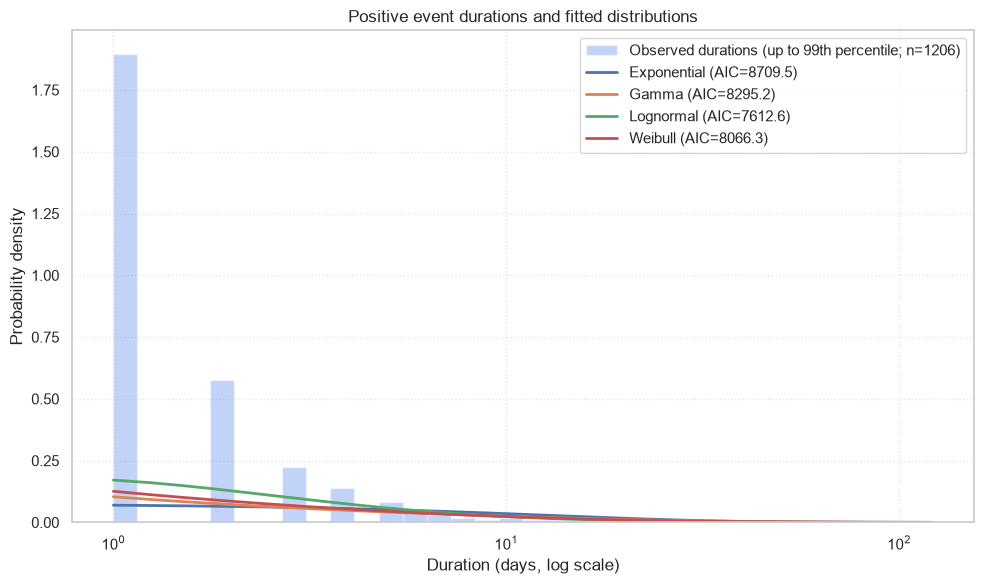

*KS p-values are descriptive: standard KS p-values do not account for
  distribution parameters estimated from the same data.


In [151]:
date_parts = ["Start Year", "Start Month", "Start Day", "End Year", "End Month", "End Day"]
for col in date_parts:
    data_duration[col] = pd.to_numeric(data_duration[col], errors="coerce")

duration_source = data_duration.dropna(subset=date_parts)
for col in date_parts:
    duration_source[col] = duration_source[col].astype(int)

duration_source["start_date"] = pd.to_datetime({
    "year": duration_source["Start Year"],
    "month": duration_source["Start Month"],
    "day": duration_source["Start Day"],
}, errors="coerce")

duration_source["end_date"] = pd.to_datetime({
    "year": duration_source["End Year"],
    "month": duration_source["End Month"],
    "day": duration_source["End Day"],
}, errors="coerce")

duration_source["duration_days"] = (
    duration_source["end_date"] - duration_source["start_date"]
).dt.days

valid_duration = duration_source.loc[
    duration_source["duration_days"].notna()
    & (duration_source["duration_days"] >= 0),
    "duration_days",
].astype(int)

positive_durations = valid_duration[valid_duration > 0].to_numpy()

print(f"Events with valid, non-negative durations: {len(valid_duration)}")
print(f"Zero-day events: {(valid_duration == 0).sum()}")
print(f"Positive-duration events used for fitting: {len(positive_durations)}")
print("\nDuration summary (days):")
print(valid_duration.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

if len(positive_durations) < 2:
    print("\nNot enough positive durations to fit distributions.")
else:
    # Fit continuous distributions with location fixed at zero.
    candidates = {
        "Exponential": (stats.expon, 1),
        "Gamma": (stats.gamma, 2),
        "Lognormal": (stats.lognorm, 2),
        "Weibull": (stats.weibull_min, 2),
    }

    fit_results = []
    fitted = {}

    for name, (distribution, n_parameters) in candidates.items():
        params = distribution.fit(positive_durations, floc=0)
        log_likelihood = np.sum(distribution.logpdf(positive_durations, *params))
        aic = 2 * n_parameters - 2 * log_likelihood
        bic = n_parameters * np.log(len(positive_durations)) - 2 * log_likelihood
        ks_stat, ks_pvalue = stats.kstest(
            positive_durations, distribution.cdf, args=params
        )

        fitted[name] = (distribution, params)
        fit_results.append({
            "Distribution": name,
            "AIC": aic,
            "BIC": bic,
            "KS statistic": ks_stat,
            "KS p-value*": ks_pvalue,
        })

    fit_summary = pd.DataFrame(fit_results).sort_values("AIC").reset_index(drop=True)
    display(fit_summary.round(4))

    # Plot the observed distribution and fitted probability densities.
    upper = np.quantile(positive_durations, 0.99)
    plot_data = positive_durations[positive_durations <= upper]
    bins = np.geomspace(max(0.5, plot_data.min()), plot_data.max() + 1, 35)
    x_grid = np.linspace(positive_durations.min(), upper, 500)

    plt.figure(figsize=(10, 6))
    plt.hist(
        plot_data,
        bins=bins,
        density=True,
        alpha=0.4,
        color="cornflowerblue",
        edgecolor="white",
        label=f"Observed durations (up to 99th percentile; n={len(plot_data)})",
    )

    for name, (distribution, params) in fitted.items():
        aic = fit_summary.loc[fit_summary["Distribution"] == name, "AIC"].iloc[0]
        plt.plot(
            x_grid,
            distribution.pdf(x_grid, *params),
            linewidth=2,
            label=f"{name} (AIC={aic:.1f})",
        )

    plt.xscale("log")
    plt.xlabel("Duration (days, log scale)")
    plt.ylabel("Probability density")
    plt.title("Positive event durations and fitted distributions")
    plt.grid(True, linestyle=":", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("*KS p-values are descriptive: standard KS p-values do not account for")
    print("  distribution parameters estimated from the same data.")

In [ ]:
durations = data_raw['duration_days'][data_raw['duration_days'] > 0].astype(int).to_numpy()